# ランキング問題と順位評価指標（Kendall's τ・Spearman's ρ・nDCG）

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mamorlis/nlpbook/blob/main/notebooks/ch2_ranking.ipynb)

書籍 第2章「分類・回帰問題の解き方」（2-3 文章の品質推定：2-3-1 問題の定式化、2-3-3 評価、練習問題 4）に対応する演習ノートブックです。
第5章の宿泊レビューフレーズデータ（`phrase-annotation.csv`、1〜5 の 5 段階評価つき 100 件）を使い、CPU のみ・数秒で以下を体験します。

1. **ランキング評価指標（Kendall の $\tau$・Spearman の $\rho$・nDCG@k）の実装とライブラリ検証**
2. **Pointwise 回帰 vs Pairwise ランキングの比較（5 分割交差検証）**
3. **練習問題 4 の実証**: 出力の非線形・単調スケール変換に対するランキングの不変性と、回帰の間隔尺度仮定

In [1]:
!curl -fsSLO https://raw.githubusercontent.com/mamorlis/nlpbook/refs/heads/main/misc/phrase-annotation.csv

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kendalltau, spearmanr, rankdata
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import ndcg_score
from sklearn.model_selection import KFold

df = pd.read_csv("phrase-annotation.csv").fillna({"コメント": ""})
print(f"件数: {len(df)} | 5段階スコア分布: {df['極性'].value_counts().sort_index().to_dict()}")

件数: 100 | 5段階スコア分布: {1: 18, 2: 12, 3: 32, 4: 10, 5: 28}


---

## 1. ランキング評価指標を定義式から実装・検証 (2-3-3)

品質推定や情報検索などのランキング問題では、予測値の絶対値ではなく**アイテム間の順位の整合性**を測る評価指標を使います。

- **Kendall の順位相関係数 $\tau$**（同点タイを補正する $\tau_b$）：すべてのペア $(i, j)$ のうち順序が一致した数 $C$ と逆転した数 $D$ の差を正規化
  $$\tau_b = \frac{C - D}{\sqrt{(n_0 - n_1)(n_0 - n_2)}}, \quad n_0 = \frac{n(n-1)}{2}$$
- **Spearman の順位相関係数 $\rho$**：正解と予測をそれぞれ平均順位 (average rank) へ変換したうえでのピアソン相関係数
- **nDCG@k (Normalized Discounted Cumulative Gain)**：上位 $k$ 件に高いスコアの文書が集まるほど高くなる指標（`scikit-learn` の標準定義に合わせ、位置減衰 $1 / \log_2(\text{rank} + 1)$ の線形ゲインで計算）

手動実装が `scipy.stats` および `scikit-learn` と小数第6位まで一致することを確かめます。

In [3]:
def my_kendall_tau_b(y_true, y_pred):
    """タイ補正付き Kendall の τ-b"""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    n = len(y_true)
    c = d = 0
    for i in range(n):
        for j in range(i + 1, n):
            dt = y_true[i] - y_true[j]
            dp = y_pred[i] - y_pred[j]
            if dt == 0 or dp == 0:
                continue
            if dt * dp > 0:
                c += 1
            else:
                d += 1
    def tie_pairs(arr):
        _, counts = np.unique(arr, return_counts=True)
        return int(np.sum(counts * (counts - 1) // 2))
    n0 = n * (n - 1) // 2
    n1 = tie_pairs(y_true)
    n2 = tie_pairs(y_pred)
    return float((c - d) / np.sqrt((n0 - n1) * (n0 - n2)))

def my_spearman_rho(y_true, y_pred):
    """平均順位変換後のピアソン相関係数"""
    rx = rankdata(y_true, method="average")
    ry = rankdata(y_pred, method="average")
    rx_c, ry_c = rx - rx.mean(), ry - ry.mean()
    return float(np.sum(rx_c * ry_c) / np.sqrt(np.sum(rx_c ** 2) * np.sum(ry_c ** 2)))

def my_ndcg_at_k(y_true, y_pred, k=10):
    """タイなし予測での線形ゲイン DCG@k / IDCG@k（sklearn の ndcg_score と一致）"""
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    order_pred = np.argsort(-y_pred, kind="mergesort")[:k]
    order_ideal = np.argsort(-y_true, kind="mergesort")[:k]
    discounts = np.log2(np.arange(2, len(order_pred) + 2))
    dcg = float(np.sum(y_true[order_pred] / discounts))
    idcg = float(np.sum(y_true[order_ideal] / discounts))
    return dcg / idcg if idcg > 0 else 0.0

sample_true = np.array([5, 5, 4, 3, 3, 2, 1, 5, 2, 4])
sample_pred = np.array([4.8, 3.9, 4.1, 2.5, 3.1, 1.8, 1.2, 4.5, 2.9, 3.7])

comp = pd.DataFrame([
    {
        "指標": "Kendall's tau-b",
        "手動実装": round(my_kendall_tau_b(sample_true, sample_pred), 6),
        "ライブラリ値": round(float(kendalltau(sample_true, sample_pred).statistic), 6),
    },
    {
        "指標": "Spearman's rho",
        "手動実装": round(my_spearman_rho(sample_true, sample_pred), 6),
        "ライブラリ値": round(float(spearmanr(sample_true, sample_pred).statistic), 6),
    },
    {
        "指標": "nDCG@5",
        "手動実装": round(my_ndcg_at_k(sample_true, sample_pred, k=5), 6),
        "ライブラリ値": round(float(ndcg_score([sample_true], [sample_pred], k=5)), 6),
    },
])
comp

,指標,手動実装,ライブラリ値
0,Kendall's tau-b,0.835467,0.835467
1,Spearman's rho,0.922817,0.922817
2,nDCG@5,0.995022,0.995022


---

## 2. Pointwise 回帰 vs Pairwise ランキング（5 分割交差検証）

ランキング学習には大きく分けて 3 つのアプローチがあります（書籍 2-3）。
- **Pointwise**：各文のスコアを回帰（または分類）で直接予測し、その予測値で並べる
- **Pairwise**：訓練データの 2 文の組 $(i, j)$ について **「$i$ のほうが $j$ より上位か ($y_i > y_j$)」** を識別器で学習する（特徴量差分 $x_i - x_j$ を入力し、切片なしロジスティック回帰 $\sigma(w^\top (x_i - x_j))$ を学習すると、単一文 $x$ へのスコア関数 $s(x) = w^\top x$ が直接得られます）

重要：ペア生成は**必ず訓練分割の内部だけ**で行い、テスト文との組み合わせリークを防いで評価します。

In [4]:
def pairwise_accuracy(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    correct = total = 0
    for i in range(len(y_true)):
        for j in range(i + 1, len(y_true)):
            if y_true[i] == y_true[j]:
                continue
            total += 1
            if (y_true[i] - y_true[j]) * (y_pred[i] - y_pred[j]) > 0:
                correct += 1
    return correct / total if total > 0 else 0.0

def evaluate_pointwise_vs_pairwise(texts, scores, n_splits=5):
    from scipy.sparse import vstack
    cv = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    res = {"Pointwise (Ridge)": [], "Pairwise (RankLR)": []}
    oof_scores = {"Pointwise (Ridge)": np.zeros(len(texts)), "Pairwise (RankLR)": np.zeros(len(texts))}

    for tr_idx, te_idx in cv.split(texts):
        vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(1, 3))
        X_tr = vec.fit_transform(texts.iloc[tr_idx])
        X_te = vec.transform(texts.iloc[te_idx])
        y_tr = scores.iloc[tr_idx].to_numpy()
        y_te = scores.iloc[te_idx].to_numpy()

        # 1) Pointwise Ridge 回帰
        reg = Ridge(alpha=1.0).fit(X_tr, y_tr)
        pred_pt = reg.predict(X_te)
        oof_scores["Pointwise (Ridge)"][te_idx] = pred_pt

        # 2) Pairwise Ranking（訓練内の順序付きペア x_i - x_j を生成）
        pair_diffs, pair_targets = [], []
        n_tr = len(y_tr)
        for i in range(n_tr):
            for j in range(i + 1, n_tr):
                if y_tr[i] > y_tr[j]:
                    pair_diffs.append(X_tr[i] - X_tr[j])
                    pair_targets.append(1)
                    pair_diffs.append(X_tr[j] - X_tr[i])
                    pair_targets.append(0)
                elif y_tr[i] < y_tr[j]:
                    pair_diffs.append(X_tr[j] - X_tr[i])
                    pair_targets.append(1)
                    pair_diffs.append(X_tr[i] - X_tr[j])
                    pair_targets.append(0)
        X_pairs = vstack(pair_diffs)
        ranker = LogisticRegression(fit_intercept=False, C=0.5, max_iter=1000).fit(X_pairs, pair_targets)
        pred_pw = (X_te @ ranker.coef_.ravel())
        oof_scores["Pairwise (RankLR)"][te_idx] = pred_pw

        for name, pr in [("Pointwise (Ridge)", pred_pt), ("Pairwise (RankLR)", pred_pw)]:
            res[name].append({
                "tau": float(kendalltau(y_te, pr).statistic),
                "rho": float(spearmanr(y_te, pr).statistic),
                "pair_acc": pairwise_accuracy(y_te, pr),
                "ndcg10": float(ndcg_score([y_te], [pr], k=10)),
            })
    rows = []
    for name, fold_metrics in res.items():
        mdf = pd.DataFrame(fold_metrics)
        rows.append({
            "手法": name,
            "Kendall τ": round(mdf["tau"].mean(), 3),
            "Spearman ρ": round(mdf["rho"].mean(), 3),
            "ペア正答率": round(mdf["pair_acc"].mean(), 3),
            "nDCG@10": round(mdf["ndcg10"].mean(), 3),
        })
    return pd.DataFrame(rows), oof_scores

base_summary, oof_orig = evaluate_pointwise_vs_pairwise(df["フレーズ"], df["極性"])
display(base_summary)

ranked_df = df.copy()
ranked_df["Pairwise予測スコア"] = oof_orig["Pairwise (RankLR)"].round(3)
ranked_df = ranked_df.sort_values("Pairwise予測スコア", ascending=False)
print("--- Pairwise スコア上位 4 件 ---")
display(ranked_df[["極性", "Pairwise予測スコア", "フレーズ"]].head(4))
print("--- Pairwise スコア下位 4 件 ---")
display(ranked_df[["極性", "Pairwise予測スコア", "フレーズ"]].tail(4))

,手法,Kendall τ,Spearman ρ,ペア正答率,nDCG@10
0,Pointwise (Ridge),0.427,0.535,0.743,0.873
1,Pairwise (RankLR),0.444,0.553,0.753,0.871


--- Pairwise スコア上位 4 件 ---


,極性,Pairwise予測スコア,フレーズ
44,3,2.340,全 客室 に 加湿 空気 清浄 機 を 完備 し て い て
74,5,2.070,アクセス が 良 く 観光 の 拠点 と し て 大 満足 で し た
37,5,2.066,窓 から 見え る 夜景 が 綺麗 で 大変 満足 し て お り ま す
12,3,1.890,ロビー で ウェルカム ドリンク を 配布 し て お り


--- Pairwise スコア下位 4 件 ---


,極性,Pairwise予測スコア,フレーズ
24,1,-1.601,シーツ に 前 の 宿泊 者 の もの らしい 髪の毛 が 残っ て い た
95,3,-1.709,新館 ３ 階 の 客室 の
61,1,-1.791,洗面 台 の 排水 口 の 流れ が 悪 く 水 が 溜まっ て しま う
64,2,-2.227,シャワー の 温度 調節 が 安定 せ ず 突然 水 に なっ て 困っ た


---

## 3. 練習問題 4 の実証：大小関係を保つ非線形変換に対するランキングの不変性

第 2 章 練習問題 4 では、分類・回帰・ランキングの違いとして次のように整理されています。
> **ランキング問題**：出力が**間隔尺度**や**比例尺度**のような性質（例：1→2 と 4→5 の差が等価値である）に従うという仮定が必要ない。

これを実証するため、元の 5 段階評価 $1, 2, 3, 4, 5$ の**大小順序だけを変えず**、非線形に引き伸ばしたスコア `{1: 1, 2: 2, 3: 10, 4: 40, 5: 100}` に置き換えて、再度 Pointwise 回帰と Pairwise ランキングを学習・比較します。

,モデル,変換前 Kendall τ,変換後 Kendall τ,変換前後での予測順位の一致 (τ)
0,Pointwise (Ridge 回帰),0.427,0.309,0.6727
1,Pairwise (RankLR),0.444,0.444,1.0000


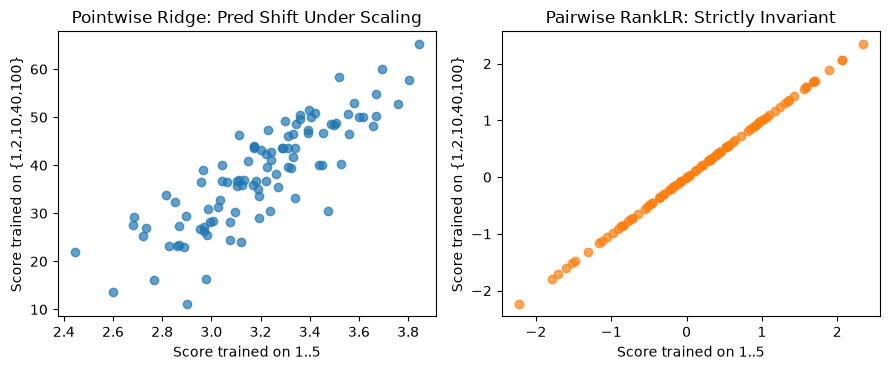

In [5]:
scale_map = {1: 1, 2: 2, 3: 10, 4: 40, 5: 100}
scaled_scores = df["極性"].map(scale_map)

scaled_summary, oof_scaled = evaluate_pointwise_vs_pairwise(df["フレーズ"], scaled_scores)

rank_consistency = pd.DataFrame([
    {
        "モデル": "Pointwise (Ridge 回帰)",
        "変換前 Kendall τ": float(base_summary.loc[0, "Kendall τ"]),
        "変換後 Kendall τ": float(scaled_summary.loc[0, "Kendall τ"]),
        "変換前後での予測順位の一致 (τ)": round(float(kendalltau(oof_orig["Pointwise (Ridge)"], oof_scaled["Pointwise (Ridge)"]).statistic), 4),
    },
    {
        "モデル": "Pairwise (RankLR)",
        "変換前 Kendall τ": float(base_summary.loc[1, "Kendall τ"]),
        "変換後 Kendall τ": float(scaled_summary.loc[1, "Kendall τ"]),
        "変換前後での予測順位の一致 (τ)": round(float(kendalltau(oof_orig["Pairwise (RankLR)"], oof_scaled["Pairwise (RankLR)"]).statistic), 4),
    },
])
display(rank_consistency)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
axes[0].scatter(oof_orig["Pointwise (Ridge)"], oof_scaled["Pointwise (Ridge)"], alpha=0.7)
axes[0].set_title("Pointwise Ridge: Pred Shift Under Scaling")
axes[0].set_xlabel("Score trained on 1..5")
axes[0].set_ylabel("Score trained on {1,2,10,40,100}")

axes[1].scatter(oof_orig["Pairwise (RankLR)"], oof_scaled["Pairwise (RankLR)"], alpha=0.7, color="tab:orange")
axes[1].set_title("Pairwise RankLR: Strictly Invariant")
axes[1].set_xlabel("Score trained on 1..5")
axes[1].set_ylabel("Score trained on {1,2,10,40,100}")

plt.tight_layout()
plt.show()

### まとめ

- **Pointwise 回帰（二乗誤差最小化）** は数値の大小間隔（1と2の差＝4と5の差）に引っ張られるため、評価尺度を単調に伸び縮みさせるだけで予測スコアや順序が変わることがあります。
- **Pairwise ランキング** は「どちらが上か ($y_i > y_j$)」の順序関係だけから学習するため、この実験では大小関係を保つ変換の前後で **予測順位が一致 ($\tau = 1.0000$)** であり、間隔尺度の仮定を置けない人手評価・品質推定タスクに適しています。